[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C4_NB07_bifurcation_toolkit.ipynb)

# Day 2 · Chapter 4 · Notebook 07 — A bifurcation toolkit

**Goal.** On Day 1 we met bifurcations at every scale, one model at a time. Today we look at them on their own,
in their simplest form, and ask the question that matters for whole-brain models: **why would a brain region,
or a model of it, sit close to a bifurcation?**

| where we met it | bifurcation | what changes |
|---|---|---|
| QIF, theta, active rotator (NB02) | saddle-node (on invariant circle) | rest → firing, at any low rate |
| Hodgkin–Huxley (NB01) | subcritical Hopf | rest → firing, with bistability |
| excitatory + inhibitory populations (this notebook, §0) | Hopf | steady activity → E–I oscillation |
| QIF population, MPR (NB05) | two saddle-nodes | low ↔ high activity, hysteresis |
| active-rotator population (NB06) | Hopf / limit cycle | stationary ↔ collective oscillations |

**Vocabulary.**
* *State space*: the space of all variables. *Attractor*: where trajectories end up (a stable fixed point, a limit cycle...).
* *Control parameter*: a parameter we turn slowly (input current, coupling, airspeed...).
* *Bifurcation*: a value of the parameter at which the attractors change qualitatively (appear, disappear, change stability).
* *Normal form*: the simplest equation that has a given bifurcation. Close to the bifurcation, **every** system with that
  bifurcation behaves like its normal form, whatever the details (this is why the QIF describes any type-I neuron near
  threshold, NB02). Normal forms are the universal "maps" of dynamics.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import normal_forms as nf, networks, meanfield
from src.plotting import show_movie
from matplotlib.animation import FuncAnimation
os.makedirs('../figures/videos', exist_ok=True)

## 0. Warm-up: excitatory and inhibitory populations

Every cortical circuit contains excitatory and inhibitory neurons (NB01, section 7), wired to each other. Wilson and Cowan
(1972) described such a circuit with one equation per population:

$$\tau_E\,\frac{dE}{dt} = -E + S_E\big(w_{EE}E - w_{EI}I + P\big),\qquad
  \tau_I\,\frac{dI}{dt} = -I + S_I\big(w_{IE}E - w_{II}I + Q\big)$$

$E$ and $I$ are the activities of the two populations; $S$ is the S-shaped response of a population to its input
(firing rate vs input, as in NB05); $E$ excites itself and $I$ ($w_{EE}, w_{IE}$), $I$ inhibits $E$ ($w_{EI}$); $P$ is
the input from outside. Compare two circuits: one with almost no inhibition, one with it.

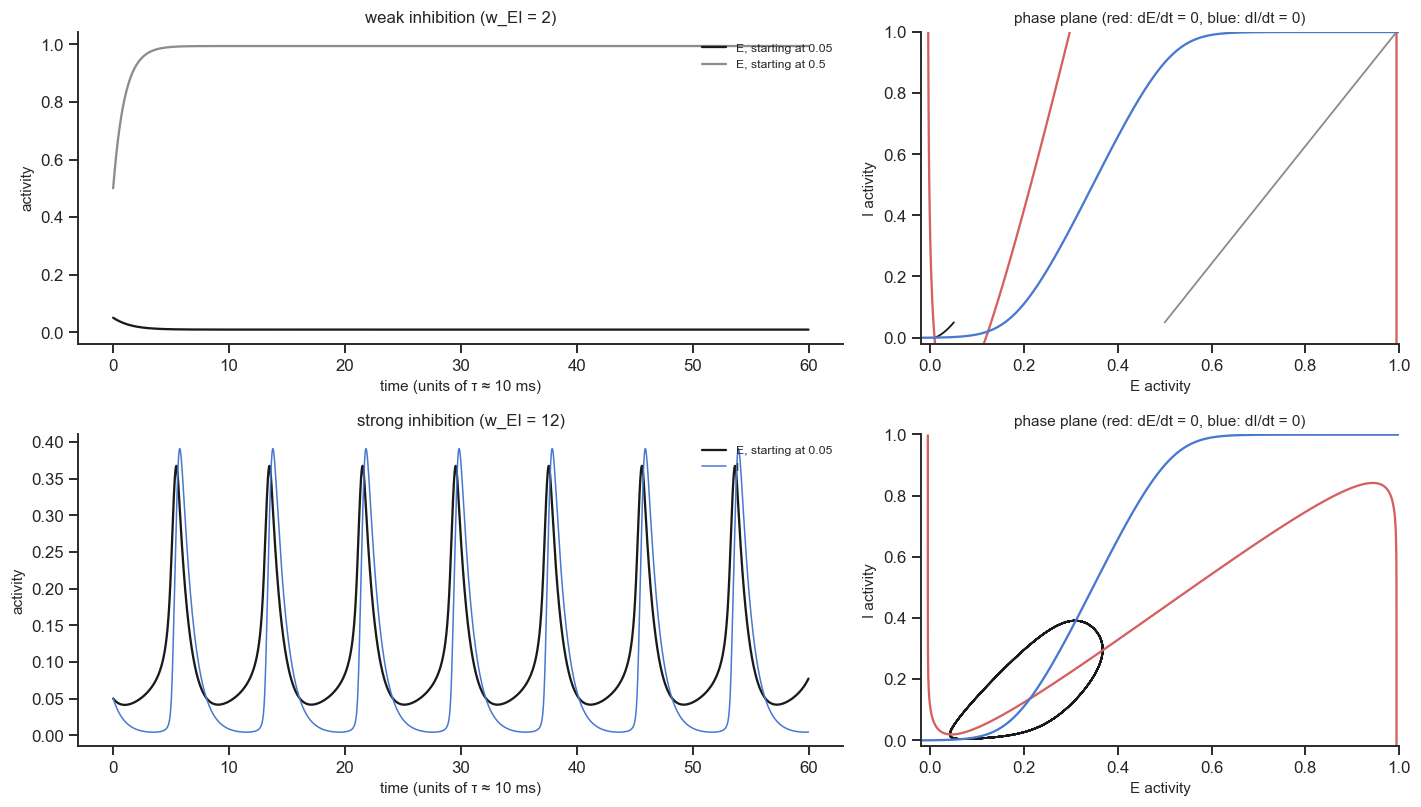

In [2]:
def wc_field(ax, P, wEI, Q=0.0):
    # nullclines: where dE/dt = 0 (red) and dI/dt = 0 (blue)
    e, i = np.meshgrid(np.linspace(-0.02, 1, 300), np.linspace(-0.02, 1, 300)); p = meanfield.WC
    dE = -e + meanfield.wc_sigmoid(p["wEE"] * e - wEI * i + P, p["aE"], p["thE"])
    dI = -i + meanfield.wc_sigmoid(p["wIE"] * e - p["wII"] * i + Q, p["aI"], p["thI"])
    ax.contour(e, i, dE, [0], colors="C3", linewidths=1.5); ax.contour(e, i, dI, [0], colors="C0", linewidths=1.5)
    ax.set(xlabel="E activity", ylabel="I activity", xlim=(-0.02, 1), ylim=(-0.02, 1))

fig, ax = plt.subplots(2, 2, figsize=(13, 7.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
for row, (wEI, P, title) in enumerate([(2.0, 0.6, "weak inhibition (w_EI = 2)"), (12.0, 1.25, "strong inhibition (w_EI = 12)")]):
    starts = [(0.05, "k"), (0.5, "0.55")] if row == 0 else [(0.05, "k")]
    for E0, c in starts:
        t, E, I = meanfield.wilson_cowan(P=P, T=60, E0=E0, I0=0.05, wEI=wEI)
        ax[row, 0].plot(t, E, c=c, lw=1.5, label=f"E, starting at {E0}")
        ax[row, 1].plot(E, I, c=c, lw=1.2)
    if row: ax[row, 0].plot(t, I, c="C0", lw=1, label="I")
    wc_field(ax[row, 1], P, wEI)
    ax[row, 0].set(title=title, xlabel="time (units of τ ≈ 10 ms)", ylabel="activity"); ax[row, 0].legend(fontsize=8, loc="upper right")
    ax[row, 1].set_title("phase plane (red: dE/dt = 0, blue: dI/dt = 0)", fontsize=10)
plt.tight_layout()

* **Weak inhibition:** the excitatory population behaves like the MPR population of NB05: it has **two stable states**,
  low and high, and which one it reaches depends on where it starts (the nullclines cross three times).
* **Strong inhibition:** $E$ rises, recruits $I$, $I$ shuts $E$ down, then $I$ fades and $E$ recovers: a loop with a
  delay, which never settles. The pair **oscillates** (the nullclines cross once, at an unstable point, surrounded by a
  limit cycle). Loops between pyramidal cells and fast-spiking (PV) interneurons generate the gamma rhythm (30–80 Hz) in
  the cortex (Buzsáki & Wang 2012).

### Explore: inhibition and input
Change the strength of inhibition and the input. Where does the oscillation start and stop?

In [3]:
@interact(wEI=slider(12.0, 0.0, 16.0, 0.5, "inhibition strength w_EI"), P=slider(1.25, 0.0, 3.0, 0.05, "input to E, P"))
def explore_ei(wEI, P):
    t, E, I = meanfield.wilson_cowan(P=P, T=80, E0=0.3, I0=0.05, wEI=wEI)
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax[0].plot(t, E, "k", lw=1.5, label="E"); ax[0].plot(t, I, "C0", lw=1, label="I")
    amp = E[len(E) // 2:].max() - E[len(E) // 2:].min()
    ax[0].set(xlabel="time", ylabel="activity", ylim=(-0.02, 1), title="oscillation" if amp > 0.05 else "steady"); ax[0].legend(fontsize=8)
    ax[1].plot(E, I, "k", lw=1); wc_field(ax[1], P, wEI)
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=12.0, continuous_update=False, description='inhibition strength w_EI',…

### Game break: *Two Populations* (15 minutes)

Now you are the populations. Pair up (online: in a breakout room, or with anyone in the class), and open on your phone

**https://grabuffo.github.io/brain-modeling-course/games/two_populations.html**

Enter the class code given by the teacher and a pair number shared with your partner. Each of you gets a **secret rule**:
*Copycat* (move towards your partner's side: you receive excitation) or *Contrarian* (move away from it: you receive
inhibition). Play for 40 seconds; every 8 seconds the game kicks you both to new places. Your pair *is* a Wilson–Cowan
circuit without self-coupling, in which each population sees the other with a delay $d$, your reaction time:

$$\tau\,\frac{dx}{dt} = -x + S\big(\pm w\,[y(t-d_x) - \tfrac12]\big),\qquad
  \tau\,\frac{dy}{dt} = -y + S\big(\pm w\,[x(t-d_y) - \tfrac12]\big)$$

with $+$ for Copycat and $-$ for Contrarian. At the end the game measures your reaction times, runs these two equations
from the same start and with the same kicks, and shows whether you found their regime.

| your two cards | what you should find | in the brain |
|---|---|---|
| Copycat + Copycat (mutual excitation) | both high or both low, depending on the kick: **bistability** | up and down states (NB05) |
| Copycat + Contrarian (excitation–inhibition loop) | you chase each other: **oscillation** | E–I rhythms (this section) |
| Contrarian + Contrarian (mutual inhibition) | one high, one low: **winner takes all** | decisions, competition |

Play twice: once with the same cards from a new start, once with new cards. The teacher's board collects every pair on
one map. Your reaction time (~0.3–0.6 s) plays the role of the synaptic and conduction delays of real neurons, and it
matters: with **no delay**, a Copycat–Contrarian pair spirals into a resting point; with a delay it oscillates (a Hopf
bifurcation, section 2). In the circuit above the self-excitation $w_{EE}$ does the same job.

## 1. Saddle-node: a switch with memory

$$\frac{dx}{dt} = \mu + x - x^3 = -\frac{dU}{dx},\qquad U(x) = -\mu x - \frac{x^2}{2} + \frac{x^4}{4}$$

Think of $x$ as a ball rolling (with friction) in the landscape $U$. For $|\mu|<\mu_c = 2/(3\sqrt3)\approx0.385$ there
are two valleys (two stable states) separated by a hill (an unstable state). At $\mu=\pm\mu_c$ a valley and the hill
merge and disappear: a **saddle-node** bifurcation.

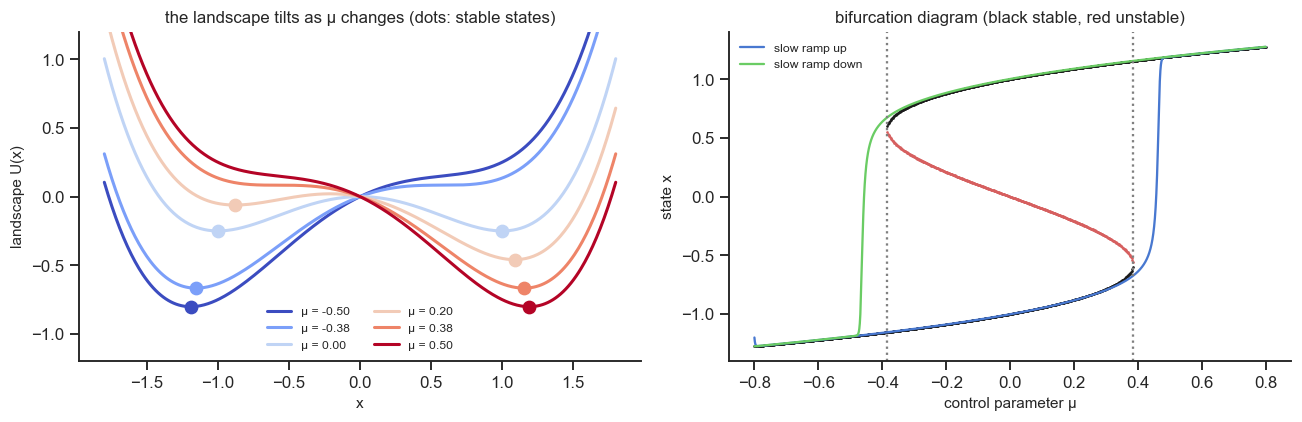

In [4]:
mu_c = 2 / (3 * np.sqrt(3))
x = np.linspace(-1.8, 1.8, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for mu, c in zip([-0.5, -mu_c, 0.0, 0.2, mu_c, 0.5], plt.cm.coolwarm(np.linspace(0, 1, 6))):
    U = -mu * x - x**2 / 2 + x**4 / 4
    ax[0].plot(x, U, c=c, lw=2, label=f"μ = {mu:.2f}")
    xs, st = nf.cusp_fixed_points(mu)
    ax[0].plot(xs[st], (-mu * xs - xs**2 / 2 + xs**4 / 4)[st], "o", c=c, ms=8)
ax[0].set(xlabel="x", ylabel="landscape U(x)", ylim=(-1.2, 1.2), title="the landscape tilts as μ changes (dots: stable states)")
ax[0].legend(fontsize=8, ncol=2)

# bifurcation diagram + slow ramp up and down (hysteresis)
mus = np.linspace(-0.8, 0.8, 801)
for mu in mus:
    xs, st = nf.cusp_fixed_points(mu)
    ax[1].plot([mu] * st.sum(), xs[st], ".", c="k", ms=1.5); ax[1].plot([mu] * (~st).sum(), xs[~st], ".", c="C3", ms=1.5)
T = 400.0; dt = 1e-2; tt = np.arange(0, T, dt)
ramp = np.where(tt < T / 2, -0.8 + 1.6 * tt / (T / 2), 0.8 - 1.6 * (tt - T / 2) / (T / 2))
_, xr = nf.cusp(0.0, T=T, dt=dt, x0=-1.2, I=ramp)          # mu enters like an input
up = tt < T / 2
ax[1].plot(ramp[up], xr[up], "C0", lw=1.5, label="slow ramp up"); ax[1].plot(ramp[~up], xr[~up], "C2", lw=1.5, label="slow ramp down")
for m in (-mu_c, mu_c): ax[1].axvline(m, c="0.5", ls=":")
ax[1].set(xlabel="control parameter μ", ylabel="state x", title="bifurcation diagram (black stable, red unstable)")
ax[1].legend(fontsize=8)
plt.tight_layout()

Going up, the system stays in the left valley until it disappears ($\mu=+\mu_c$), then jumps; going down it jumps back
only at $\mu=-\mu_c$. (The jumps come slightly after the dotted lines because the ramp has a finite speed: the system
needs time to leave a valley that has just disappeared.) This is the same hysteresis loop as the MPR population in NB05 (low/high activity): the
details differ, the normal form is the same.

## 2. Supercritical Hopf: an oscillation is born

$$\frac{dz}{dt} = (\mu + i\omega)\,z - |z|^2 z,\qquad z = x + iy = \rho\,e^{i\theta}$$

In polar coordinates: $\dot\rho = \mu\rho - \rho^3$, $\dot\theta=\omega$. For $\mu<0$ the origin is a stable focus (damped
oscillations, decay rate $|\mu|$); for $\mu>0$ it is unstable and a **limit cycle** of radius $\sqrt\mu$ appears. The
oscillation is born with zero amplitude and grows smoothly.

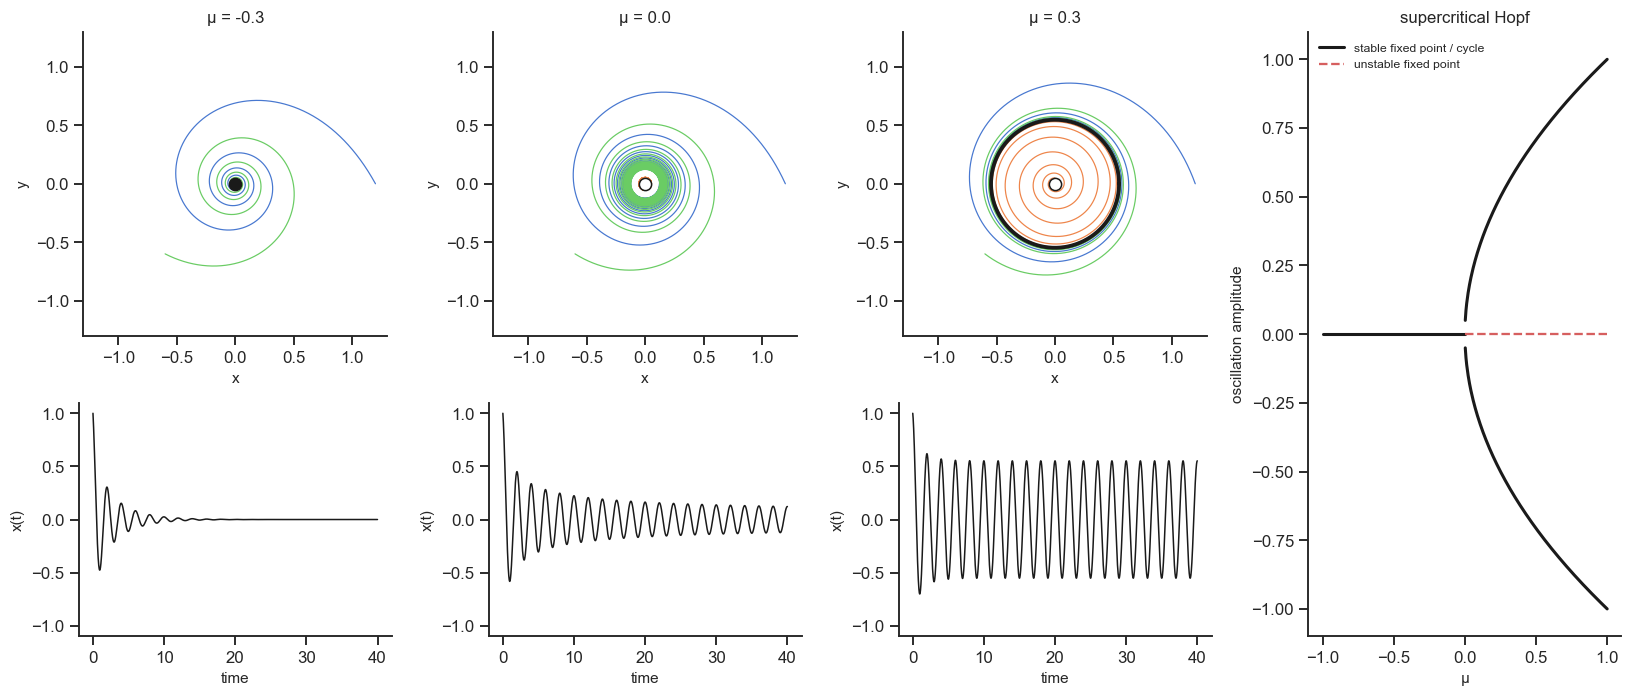

In [5]:
omega = np.pi                                   # period 2
fig, ax = plt.subplots(2, 4, figsize=(15, 6.5), gridspec_kw=dict(height_ratios=[1.3, 1]))
for k, mu in enumerate([-0.3, 0.0, 0.3]):
    for z0 in [1.2, 0.05j, -0.6 - 0.6j]:
        t, z = nf.hopf(mu, omega, T=40, dt=1e-3, z0=z0)
        ax[0, k].plot(z.real, z.imag, lw=0.8)
    if mu > 0:
        c = np.sqrt(mu) * np.exp(1j * np.linspace(0, 2 * np.pi, 200)); ax[0, k].plot(c.real, c.imag, "k", lw=2.5)
    ax[0, k].plot(0, 0, "o", mfc="k" if mu < 0 else "w", mec="k", ms=8)
    ax[0, k].set(aspect="equal", xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), title=f"μ = {mu}", xlabel="x", ylabel="y")
    t, z = nf.hopf(mu, omega, T=40, dt=1e-3, z0=1.0)
    ax[1, k].plot(t, z.real, "k", lw=1); ax[1, k].set(xlabel="time", ylabel="x(t)", ylim=(-1.1, 1.1))
ax[0, 3].remove(); ax[1, 3].remove()
axb = fig.add_subplot(1, 4, 4)
m = np.linspace(-1, 1, 400)
axb.plot(m[m < 0], 0 * m[m < 0], "k", lw=2, label="stable fixed point / cycle")
axb.plot(m[m > 0], 0 * m[m > 0], "C3--", lw=1.5, label="unstable fixed point")
axb.plot(m[m > 0], np.sqrt(m[m > 0]), "k", lw=2); axb.plot(m[m > 0], -np.sqrt(m[m > 0]), "k", lw=2)
axb.set(xlabel="μ", ylabel="oscillation amplitude", title="supercritical Hopf"); axb.legend(fontsize=8, loc="upper left")
plt.tight_layout()

### An oscillation does not need excitation and inhibition

The E–I loop of section 0 is one way to make an oscillation, but not the only one. The HH neuron under constant current
(NB01), a single population with slow self-inhibition (for example the adaptation currents that make neurons fire less
after a burst), a population of active rotators (NB06), and a wing in the wind (next section) all oscillate too. Their
mechanisms differ; what they share is the **bifurcation**: each starts oscillating through a Hopf bifurcation, and near it
each behaves like the normal form above, which has no E and no I at all.

Two practical consequences:
* An oscillation in data does not, by itself, tell us which mechanism produced it.
* Models can be matched by their bifurcations instead of their biology: the QIF neuron (NB02) reproduces the onset of
  firing of every type-I neuron; a two-dimensional "fast–slow" model reproduces the bursting of neurons that have a slow
  current on top of the HH currents (Izhikevich 2007, Ch. 9). This is why the simple models of this course can stand in
  for complicated biology, as long as the regime is the same.

## 3. An engineering example: wing flutter

An aircraft wing in an airflow can twist and bend. The structure dissipates energy (damping); the airflow can feed
energy into the motion. Below a critical airspeed $U_f$ a gust excites oscillations that die out. At $U_f$ the energy
taken from the airflow equals what the structure dissipates: the effective damping crosses zero and the wing starts to
oscillate on its own — **flutter**, a Hopf bifurcation with airspeed as control parameter. (The Tacoma Narrows bridge
collapse, 1940, is the classic example of aeroelastic flutter; Billah & Scanlan 1991.)

Model: the Hopf normal form with $\mu = 2\,(U/U_f-1)$; the wing's pitch angle is $\propto \mathrm{Re}\,z$ and its plunge
$\propto \mathrm{Im}\,z$. A gust hits all three wings at $t=2$.

In [6]:
speeds = [0.8, 0.95, 1.05]
T = 40.0; dt = 1e-3; tt = np.arange(0, T, dt)
gust = np.where((tt >= 2) & (tt < 2.2), 0.3, 0.0).astype(complex)
wings = {U: nf.hopf(2 * (U - 1), omega, T=T, dt=dt, z0=0j, I=gust)[1] for U in speeds}

xc = np.linspace(0, 1, 60)                                  # NACA 0012 airfoil
yt = 0.6 * (0.2969 * np.sqrt(xc) - 0.126 * xc - 0.3516 * xc**2 + 0.2843 * xc**3 - 0.1015 * xc**4)
foil = np.r_[xc + 1j * yt, (xc + 1j * -yt)[::-1]] - 0.25    # rotate around the quarter chord

fig, ax = plt.subplots(2, 3, figsize=(12, 5), gridspec_kw=dict(height_ratios=[1.2, 1]))
patches, cursors = [], []
for k, U in enumerate(speeds):
    z = wings[U]
    ax[1, k].plot(tt, np.degrees(1.2 * z.real), "k", lw=0.8)
    ax[1, k].set(xlabel="time", ylabel="pitch (deg)" if k == 0 else "", ylim=(-30, 30))
    cursors.append(ax[1, k].axvline(0, c="C3"))
    p, = ax[0, k].fill(foil.real, foil.imag, color="C0")
    patches.append(p)
    ax[0, k].plot([-0.6, 1.0], [0, 0], c="lightgray", lw=0.8)
    ax[0, k].set(xlim=(-0.6, 1.0), ylim=(-0.6, 0.6), aspect="equal", title=f"U = {U} $U_f$"); ax[0, k].axis("off")
plt.tight_layout()
frames = np.arange(0, int(T / dt), 100)

def update(n):
    i = frames[n]
    for k, U in enumerate(speeds):
        z = wings[U][i]
        w = foil * np.exp(-1j * 1.2 * z.real) + 1j * 0.6 * z.imag
        patches[k].set_xy(np.c_[w.real, w.imag])
        cursors[k].set_xdata([tt[i]])
    return (*patches, *cursors)

anim = FuncAnimation(fig, update, frames=len(frames), interval=50, blit=False)
plt.close(fig)
show_movie(anim, save_as="../figures/videos/NB07_wing_flutter.mp4")

* $U=0.8\,U_f$: the gust response dies out quickly.
* $U=0.95\,U_f$: the same gust gives an oscillation that lasts much longer: **close to the bifurcation the damping
  is small**.
* $U=1.05\,U_f$: the oscillation grows by itself and settles on a limit cycle (in a real wing, possibly until it breaks).

**Flight flutter testing** uses exactly this: engineers excite the wing at increasing speeds, measure the damping of the
response, and extrapolate the speed at which the damping would reach zero, without crossing it (Homework 1).
Reading the *distance to a bifurcation* from responses to perturbations is also what perturbational approaches do
in the brain (e.g. TMS-EEG), and what whole-brain models exploit (Chapter 5).

## 4. Subcritical Hopf: an oscillation that appears suddenly

$$\frac{dz}{dt} = (\mu + i\omega)\,z + |z|^2 z - |z|^4 z \qquad\Rightarrow\qquad \dot\rho = \mu\rho + \rho^3 - \rho^5$$

Now the cubic term *destabilises*. For $-\tfrac14<\mu<0$ the rest state (stable) coexists with a **large** stable limit
cycle, separated by an **unstable** cycle: bistability. At $\mu=0$ the rest state loses stability and the system jumps
to a large oscillation; to stop it, $\mu$ must go back below $-\tfrac14$. This is the Hodgkin–Huxley neuron (NB01:
a kick at the right current starts repetitive firing) and, at the population level, the hybrid transition of
Buendía et al. (NB08).

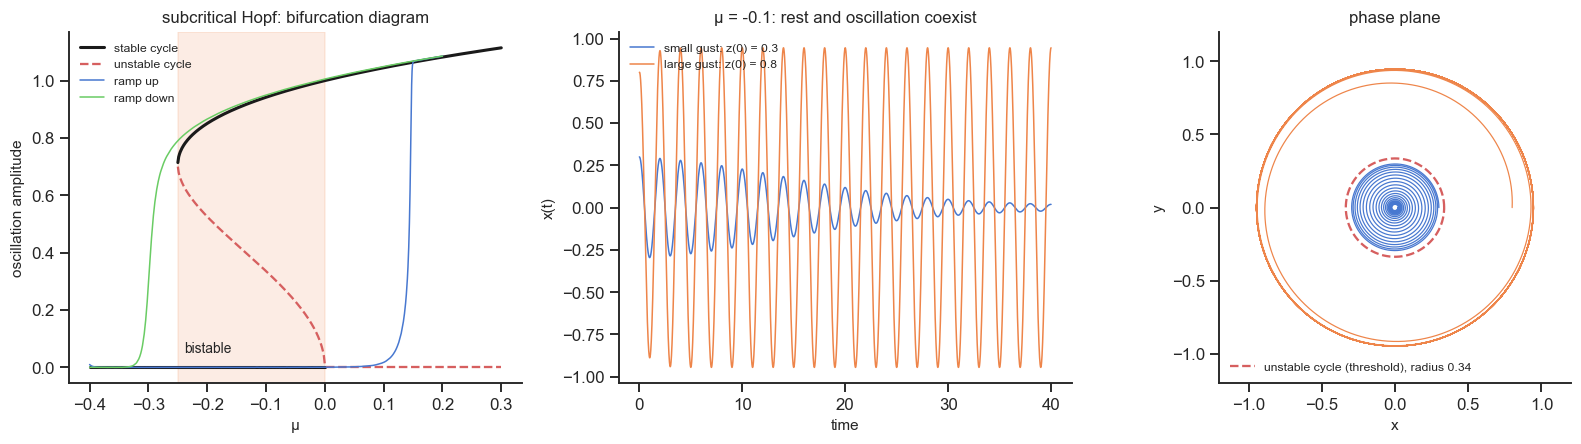

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
m = np.linspace(-0.4, 0.3, 500)
st = np.array([nf.hopf_cycles(x, "sub")[0][0] if nf.hopf_cycles(x, "sub")[0] else np.nan for x in m])
un = np.array([nf.hopf_cycles(x, "sub")[1][0] if nf.hopf_cycles(x, "sub")[1] else np.nan for x in m])
ax[0].plot(m, st, "k", lw=2, label="stable cycle"); ax[0].plot(m, un, "C3--", lw=1.5, label="unstable cycle")
ax[0].plot(m[m < 0], 0 * m[m < 0], "k", lw=2); ax[0].plot(m[m > 0], 0 * m[m > 0], "C3--", lw=1.5)
ax[0].axvspan(-0.25, 0, color="C1", alpha=0.15); ax[0].text(-0.24, 0.05, "bistable", fontsize=9)
T = 600.0; dt = 2e-3; tt = np.arange(0, T, dt)
ramp = np.where(tt < T / 2, -0.4 + 0.6 * tt / (T / 2), 0.2 - 0.6 * (tt - T / 2) / (T / 2))
_, z = nf.hopf(ramp, omega, kind="sub", sigma=1e-4, T=T, dt=dt, z0=0.01 + 0j)   # mu changes slowly in time
up = tt < T / 2
ax[0].plot(ramp[up], abs(z[up]), "C0", lw=1, label="ramp up"); ax[0].plot(ramp[~up], abs(z[~up]), "C2", lw=1, label="ramp down")
ax[0].set(xlabel="μ", ylabel="oscillation amplitude", title="subcritical Hopf: bifurcation diagram"); ax[0].legend(fontsize=8, loc="upper left")

mu = -0.1
_, r_un = nf.hopf_cycles(mu, "sub")
for k, (amp, lab) in enumerate([(0.3, "small gust"), (0.8, "large gust")]):
    t, z = nf.hopf(mu, omega, kind="sub", T=40, dt=1e-3, z0=amp)
    ax[1].plot(t, z.real, lw=1, label=f"{lab}: z(0) = {amp}")
    ax[2].plot(z.real, z.imag, lw=0.8)
c = np.exp(1j * np.linspace(0, 2 * np.pi, 200))
ax[2].plot(r_un[0] * c.real, r_un[0] * c.imag, "C3--", lw=1.5, label=f"unstable cycle (threshold), radius {r_un[0]:.2f}")
ax[1].set(xlabel="time", ylabel="x(t)", title=f"μ = {mu}: rest and oscillation coexist"); ax[1].legend(fontsize=8)
ax[2].set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xlabel="x", ylabel="y", title="phase plane"); ax[2].legend(fontsize=8, loc="lower left")
plt.tight_layout()

(In the ramp, the jump up happens well after $\mu=0$: when a parameter crosses a Hopf bifurcation slowly, the
system stays near the now-unstable rest state for a while before leaving it, the *delayed* or *slow passage* effect.
Noise shortens the delay.)

The difference with the supercritical case matters in practice: a supercritical oscillation starts small and can be
stopped by reversing the parameter a little; a subcritical one starts **large and suddenly**, can be triggered by a large
enough perturbation *before* the bifurcation, and does not stop when the parameter is reversed a little. (Aircraft
engineers fear subcritical flutter for the same reason.)

### Explore: super- and subcritical Hopf

* Supercritical: how does the amplitude of the oscillation depend on $\mu$ above 0? How long do the transients last
  below 0, close to 0?
* Subcritical, $\mu=-0.1$: find the smallest kick that starts the oscillation. Compare it with the radius of the unstable cycle.
* Subcritical, $\mu=-0.3$: can any kick start a sustained oscillation?

In [8]:
@interact(kind=["super", "sub"], mu=slider(-0.1, -0.5, 0.5, 0.01, "μ"), kick=slider(0.5, 0.0, 1.5, 0.05, "kick |z(0)|"))
def explore_hopf(kind, mu, kick):
    t, z = nf.hopf(mu, omega, kind=kind, T=60, dt=1e-3, z0=kick + 0j)
    st, un = nf.hopf_cycles(mu, kind)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1, 1.2]))
    ax[0].plot(t, z.real, "k", lw=1); ax[0].set(xlabel="time", ylabel="x(t)", ylim=(-1.3, 1.3), title=f"{kind}critical Hopf, μ = {mu}")
    c = np.exp(1j * np.linspace(0, 2 * np.pi, 200))
    ax[1].plot(z.real, z.imag, "k", lw=0.6)
    for r in st: ax[1].plot(r * c.real, r * c.imag, "C2", lw=2)
    for r in un: ax[1].plot(r * c.real, r * c.imag, "C3--", lw=1.5)
    ax[1].set(aspect="equal", xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), title="phase plane"); ax[1].axis("off")
    m = np.linspace(-0.5, 0.5, 400)
    for x in m:
        s_, u_ = nf.hopf_cycles(x, kind)
        ax[2].plot([x] * len(s_), s_, ".", c="k", ms=1.5); ax[2].plot([x] * len(u_), u_, ".", c="C3", ms=1.5)
    ax[2].plot(m[m < 0], 0 * m[m < 0], "k", lw=2); ax[2].plot(m[m > 0], 0 * m[m > 0], "C3--")
    ax[2].axvline(mu, c="C0"); ax[2].set(xlabel="μ", ylabel="amplitude", ylim=(-0.05, 1.2), title="bifurcation diagram")
    plt.tight_layout(); plt.show()

interactive(children=(Dropdown(description='kind', options=('super', 'sub'), value='super'), FloatSlider(value…

## 5. Why bifurcations matter: sensitivity

Close to a bifurcation (on the stable side) the restoring force is weak: the largest eigenvalue $\lambda$ of the
stable state is close to 0. Two consequences, both measurable:

1. **Responses to perturbations are larger and last longer** (decay time $1/|\lambda|$): the wing at $0.95\,U_f$.
2. **Noise is turned into large, slow fluctuations**: for the noisy Hopf normal form
   $\dot z = (\mu+i\omega)z + \sigma\,\xi(t)$ (with $\mu<0$) the theory gives
   $$\mathrm{Var}(x) = \frac{\sigma^2}{2|\mu|},\qquad \text{correlation time} = \frac{1}{|\mu|},$$
   both diverging as $\mu\to0$. This is **critical slowing down**, the same phenomenon we saw just above the
   synchronisation transition in NB04.

at mu = 0 (on the bifurcation): variance 0.0107, correlation time 84


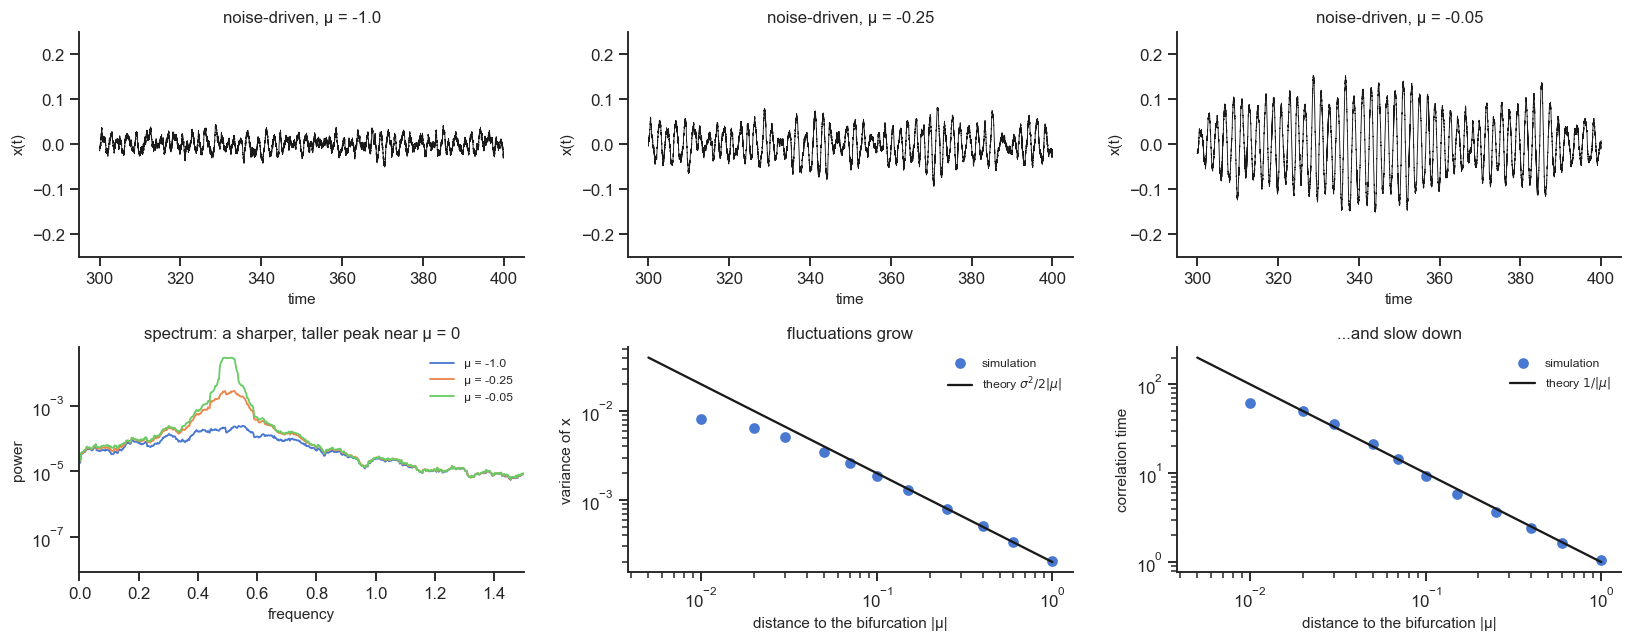

In [9]:
sigma = 0.02
mus_show = [-1.0, -0.25, -0.05]
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for k, mu in enumerate(mus_show):
    t, z = nf.hopf(mu, omega, sigma=sigma, T=400, dt=1e-3, z0=0j, seed=1)
    ax[0, k].plot(t[t > 300], z.real[t > 300], "k", lw=0.6)
    ax[0, k].set(xlabel="time", ylabel="x(t)", ylim=(-0.25, 0.25), title=f"noise-driven, μ = {mu}")
    x = z.real[t > 20][::20]
    f = np.fft.rfftfreq(x.size, 0.02); P = np.abs(np.fft.rfft(x))**2 * 0.02 / x.size
    ax[1, 0].semilogy(f, np.convolve(P, np.ones(20) / 20, "same"), lw=1.2, label=f"μ = {mu}")
ax[1, 0].set(xlim=(0, 1.5), xlabel="frequency", ylabel="power", title="spectrum: a sharper, taller peak near μ = 0")
ax[1, 0].legend(fontsize=8)

mus = np.array([-1.0, -0.6, -0.4, -0.25, -0.15, -0.1, -0.07, -0.05, -0.03, -0.02, -0.01, 0.0])
var, tau = [], []
for mu in mus:
    t, z = nf.hopf(mu, omega, sigma=sigma, T=800, dt=1e-3, z0=0j, seed=2)
    zz = z[t > 50][::50]
    var.append(zz.real.var()); tau.append(nf.autocorr_time(zz, 0.05)[0])
mt = np.linspace(-1, -0.005, 200)
ax[1, 1].loglog(-mus[mus < 0], np.array(var)[mus < 0], "o", c="C0", label="simulation")
ax[1, 1].loglog(-mt, sigma**2 / (2 * -mt), "k", label=r"theory $\sigma^2/2|\mu|$")
ax[1, 1].set(xlabel="distance to the bifurcation |μ|", ylabel="variance of x", title="fluctuations grow"); ax[1, 1].legend(fontsize=8)
ax[1, 2].loglog(-mus[mus < 0], np.array(tau)[mus < 0], "o", c="C0", label="simulation")
ax[1, 2].loglog(-mt, 1 / -mt, "k", label=r"theory $1/|\mu|$")
ax[1, 2].set(xlabel="distance to the bifurcation |μ|", ylabel="correlation time", title="...and slow down"); ax[1, 2].legend(fontsize=8)
plt.tight_layout()
print(f"at mu = 0 (on the bifurcation): variance {var[-1]:.4f}, correlation time {tau[-1]:.0f}")

Far from the bifurcation the fluctuations are small and fast; close to it they are large, slow and strongly rhythmic
(sharp spectral peak). Very close, the simulation departs from the linear theory and stays finite: the nonlinear
term $-|z|^2z$ takes over.

### The spiking population near its saddle-node

Is this only a property of toy equations? Take the 10 000-neuron QIF network of NB03/NB05 in its low-activity state and
move it towards the saddle-node at $I_{SN}\approx1.86$ by increasing a constant input $I$. At $t=20$ we give the **same**
short pulse (amplitude 1, duration 1) and look at the response.

saddle-node at I_SN = 1.863; at I = 1.8 the pulse switches the whole population to high activity (integrated response 41)


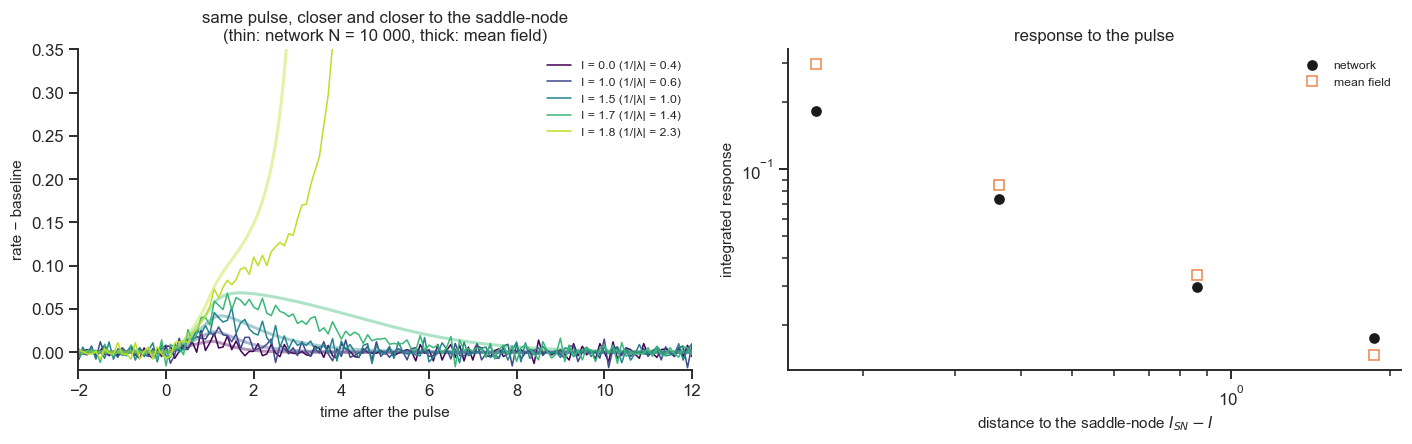

In [10]:
I_sn = max(x[0] for x in meanfield.mpr_branches(np.linspace(0, 2, 2001), -5.0, 15.0) if not x[3])   # upper saddle-node
dtp = 5e-4; Tp = 60.0; tp = np.arange(0, Tp, dtp)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
resp = []
for I0, c in zip([0.0, 1.0, 1.5, 1.7, 1.8], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    Ip = np.full(tp.size, I0); Ip[(tp >= 20) & (tp < 21)] += 1.0
    tb, r_n, *_ = networks.qif_network(Ip, N=10000, dt=dtp, bin_size=0.1, seed=0)
    r0, v0 = meanfield.mpr_fixed_points(-5.0, 15.0, I=I0)[0]
    r_m, _ = meanfield.mpr(Ip, dt=dtp, r0=r0, v0=v0)
    lam = max(np.linalg.eigvals(meanfield.mpr_jacobian(r0, v0, 15.0)).real)
    base = r_n[(tb > 10) & (tb < 20)].mean()
    ax[0].plot(tb - 20, r_n - base, c=c, lw=1, label=f"I = {I0} (1/|λ| = {1 / abs(lam):.1f})")
    ax[0].plot(tp - 20, r_m - r0, c=c, lw=2, alpha=0.4)
    resp.append((I_sn - I0, np.sum((r_n - base)[tb > 20]) * 0.1, np.sum(r_m[tp > 20] - r0) * dtp))
ax[0].set(xlim=(-2, 12), ylim=(-0.02, 0.35), xlabel="time after the pulse", ylabel="rate − baseline",
          title="same pulse, closer and closer to the saddle-node\n(thin: network N = 10 000, thick: mean field)")
ax[0].legend(fontsize=8)
d, rn, rm = np.array(resp).T
ax[1].loglog(d[:-1], rn[:-1], "o", c="k", label="network"); ax[1].loglog(d[:-1], rm[:-1], "s", mfc="none", c="C1", label="mean field")
ax[1].set(xlabel=r"distance to the saddle-node $I_{SN} - I$", ylabel="integrated response", title="response to the pulse")
ax[1].legend(fontsize=8)
plt.tight_layout()
print(f"saddle-node at I_SN = {I_sn:.3f}; at I = 1.8 the pulse switches the whole population to high activity (integrated response {rn[-1]:.0f})")

The same pulse produces a tiny response far from the bifurcation, a response ~30 times larger and much longer close to
it, and at $I=1.8$ it **switches the whole population** to the high-activity state. The spiking network behaves like the
normal form.

With noise added to the population (as in whole-brain models, where each region receives noisy input), the same
closeness to the bifurcation shows up in the fluctuations, and very close to it noise alone can switch the state:

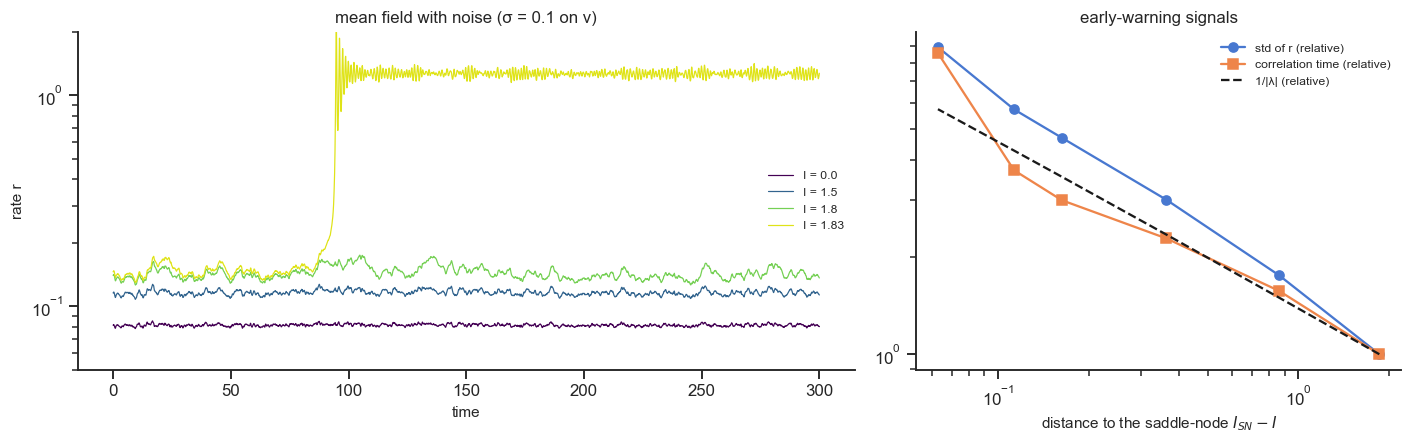

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
dtn = 1e-3; Tn = 300.0; n = int(Tn / dtn)
stats = []
for k, (I0, c) in enumerate(zip([0.0, 1.0, 1.5, 1.7, 1.75, 1.8, 1.83], plt.cm.viridis(np.linspace(0, 0.95, 7)))):
    r0, v0 = meanfield.mpr_fixed_points(-5.0, 15.0, I=I0)[0]
    r_m, _ = meanfield.mpr(np.full(n, I0), dt=dtn, r0=r0, v0=v0, noise_v=0.1, seed=0)
    tn = np.arange(n) * dtn
    if I0 in (0.0, 1.5, 1.8, 1.83):
        ax[0].plot(tn, r_m, c=c, lw=0.8, label=f"I = {I0}")
    if r_m.max() < 0.5:
        x = r_m[int(20 / dtn)::100]
        lam = max(np.linalg.eigvals(meanfield.mpr_jacobian(r0, v0, 15.0)).real)
        stats.append((I_sn - I0, x.std(), nf.autocorr_time(x, 0.1)[0], 1 / abs(lam)))
ax[0].set(xlabel="time", ylabel="rate r", yscale="log", ylim=(0.05, 2), title="mean field with noise (σ = 0.1 on v)")
ax[0].legend(fontsize=8, loc="center right")
d, sd, tau_r, tau_th = np.array(stats).T
ax[1].loglog(d, sd / sd[0], "o-", label="std of r (relative)"); ax[1].loglog(d, tau_r / tau_r[0], "s-", label="correlation time (relative)")
ax[1].loglog(d, tau_th / tau_th[0], "k--", label="1/|λ| (relative)")
ax[1].set(xlabel=r"distance to the saddle-node $I_{SN}-I$", title="early-warning signals"); ax[1].legend(fontsize=8)
plt.tight_layout()

As the population approaches the saddle-node its fluctuations grow and slow down (left: compare $I=0$ and $I=1.8$),
following the eigenvalue of the low state. At $I=1.83$, still on the "safe" side of the bifurcation, noise kicks the
population over the hill and it switches to high activity. Growing variance and autocorrelation are used as
**early-warning signals** of critical transitions in ecology, climate and medicine (Scheffer et al. 2009).

### Explore: noise-driven Hopf

* Move $\mu$ from $-1$ towards 0 with fixed noise: watch amplitude, spectrum and autocorrelation.
* Cross to $\mu>0$: how do the fluctuations look now? Is the autocorrelation still decaying?
* At $\mu=-0.05$, double the noise: does the variance follow $\sigma^2/2|\mu|$?

In [12]:
@interact(mu=slider(-0.2, -1.0, 0.3, 0.01, "μ"), sigma=slider(0.02, 0.0, 0.1, 0.005, "noise σ"))
def explore_noisy_hopf(mu, sigma):
    t, z = nf.hopf(mu, omega, sigma=sigma, T=400, dt=1e-3, z0=0j, seed=3)
    zz = z[t > 20][::20]
    tau, ac = nf.autocorr_time(zz, 0.02)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
    ax[0].plot(t[t > 300], z.real[t > 300], "k", lw=0.7)
    th = f", theory {sigma**2 / (2 * abs(mu)):.5f}" if mu < 0 else ""
    ax[0].set(xlabel="time", ylabel="x(t)", title=f"var(x) = {zz.real.var():.5f}{th}")
    x = zz.real; f = np.fft.rfftfreq(x.size, 0.02); P = np.abs(np.fft.rfft(x))**2 * 0.02 / x.size
    ax[1].semilogy(f, np.convolve(P, np.ones(20) / 20, "same"), "k"); ax[1].set(xlim=(0, 1.5), xlabel="frequency", ylabel="power", title="spectrum")
    lag = np.arange(ac.size) * 0.02
    ax[2].plot(lag, ac, "k"); ax[2].axhline(np.exp(-1), c="gray", ls=":")
    ax[2].set(xlim=(0, min(100, lag[-1])), xlabel="lag", ylabel="|autocorrelation|", title=f"correlation time {tau:.1f}" + (f" (theory {1 / abs(mu):.1f})" if mu < 0 else ""))
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=-0.2, continuous_update=False, description='μ', layout=Layout(width='4…

### What sets the distance to a bifurcation in a real brain?

In a model we turn a parameter ($\mu$, $I$, $\eta$, $w_{EI}$, the coupling $G$). In the brain the same role is played by
several biological dials:
* **Neuromodulators.** Acetylcholine, noradrenaline, serotonin and dopamine are released by small groups of neurons in the
  brainstem and basal forebrain whose axons reach the whole cortex. They change how excitable neurons are and how strongly
  they respond, for example by closing potassium channels and reducing adaptation (McCormick 1992; Marder 2012). In deep
  (non-REM) sleep, acetylcholine and noradrenaline fall and the cortex enters the slow oscillation of up and down states,
  the bistable regime of NB05; on waking they rise again and the cortex leaves that regime (Steriade, McCormick &
  Sejnowski 1993).
* **The balance of excitation and inhibition** ($w_{EI}$ in section 0 moves the circuit across a Hopf bifurcation). Many
  drugs act here; anaesthetics such as propofol, for example, strengthen GABA$_A$ inhibition.
* **Input from other regions** (the coupling $G$ of Chapter 5), and slower factors such as extracellular ion
  concentrations, development and disease.

So the distance to a bifurcation is not a fixed property: the brain turns these dials from moment to moment (sleep and
waking, arousal, attention) and over a lifetime.

## 6. Take-home: why whole-brain models are tuned near a bifurcation

* Two populations, one excitatory and one inhibitory, already show the main regimes: bistability with weak inhibition,
  oscillation with strong inhibition. But an oscillation does not need E and I: what models share is the bifurcation.
* Bifurcations come in a few universal types (saddle-node, super- and subcritical Hopf, ...); near the bifurcation any
  system behaves like the normal form. This is why simple models can stand in for complicated ones.
* Close to a bifurcation, on the stable side, a system (a wing, a neuron, a population):
  1. **responds strongly and for a long time** to perturbations — inputs from other brain regions have an effect;
  2. **turns noise into large, slow, rhythmic fluctuations** — the kind of slow, structured activity we see in fMRI;
  3. can **switch between states** with small pushes (multistability, subcritical transitions).
* Far from the bifurcation the model is too stable (activity just mirrors the noise); across it the model is dominated by
  its own oscillation or state. The **working point** of realistic whole-brain models is close to, but not across, the
  bifurcation (Deco & Jirsa 2012; Deco et al. 2017; Chapter 5).
* In the brain, neuromodulators, the E/I balance and input from other regions set how close a region is to a bifurcation.
* **Next:** NB08 — the bifurcations of the active-rotator population and what happens *at* them: criticality.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **Flutter test.** Simulate gust responses (Section 3) at $U/U_f = 0.6, 0.7, 0.8, 0.85$. Fit the decay rate of the
   envelope $|z(t)|$ (a straight line in log scale) at each speed and extrapolate linearly to the speed where it vanishes.
   How close do you get to $U_f$?
2. **The ghost of a saddle-node.** Just past the saddle-node ($\mu$ slightly larger than $\mu_c$ in Section 1) there is no
   fixed point, but the system slows down where it used to be. Measure the time to go from $x=-1.5$ to $x=1$ as a function
   of $\mu-\mu_c$ and show that it scales as $(\mu-\mu_c)^{-1/2}$. Where have you seen this law before? (Hint: NB02, the
   firing rate of the QIF near threshold.)
3. **Subcritical threshold.** For the subcritical Hopf, find the smallest kick that starts a sustained oscillation at
   $\mu=-0.05,-0.1,-0.2$ and compare it with the radius of the unstable cycle.
4. **Early warning in practice.** Using only the variance of noisy MPR simulations at a few inputs $I$, estimate the position
   of the saddle-node $I_{SN}$ (hint: $1/\mathrm{Var}$ is roughly linear in the distance to the bifurcation).
5. **Waiting to switch.** At $I=1.83$, $\sigma=0.1$, measure the time until noise switches the MPR population up, over
   20 seeds. Repeat at $I=1.81$ and $1.85$.

### References
* Wilson HR, Cowan JD (1972). Excitatory and inhibitory interactions in localized populations of model neurons. *Biophys J* 12:1–24.
* Buzsáki G, Wang X-J (2012). Mechanisms of gamma oscillations. *Annu Rev Neurosci* 35:203–225.
* McCormick DA (1992). Neurotransmitter actions in the thalamus and cerebral cortex and their role in neuromodulation of thalamocortical activity. *Prog Neurobiol* 39:337–388.
* Steriade M, McCormick DA, Sejnowski TJ (1993). Thalamocortical oscillations in the sleeping and aroused brain. *Science* 262:679–685.
* Marder E (2012). Neuromodulation of neuronal circuits: back to the future. *Neuron* 76:1–11.
* Strogatz SH (2015). *Nonlinear Dynamics and Chaos*, 2nd ed. Westview. (Ch. 3 and 8: saddle-node, Hopf.)
* Izhikevich EM (2007). *Dynamical Systems in Neuroscience*. MIT Press. (Ch. 6–7: bifurcations of neurons.)
* Kuznetsov YA (2004). *Elements of Applied Bifurcation Theory*, 3rd ed. Springer.
* Billah KY, Scanlan RH (1991). Resonance, Tacoma Narrows bridge failure, and undergraduate physics textbooks. *Am J Phys* 59:118–124.
* Scheffer M et al. (2009). Early-warning signals for critical transitions. *Nature* 461:53–59.
* Deco G, Jirsa VK (2012). Ongoing cortical activity at rest: criticality, multistability, and ghost attractors. *J Neurosci* 32:3366–3375.
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and its dynamical cortical core. *Sci Rep* 7:3095.